# Pair 2 — Qwen3.5-4B vs Gemma 4 E4B

**Amazon product search: ESCI classification and ranking**

Both models were tested on the same 400 classification cases and 33 ranking queries. This notebook compares their results and looks at mistakes.

## 1. Setup

Load the saved predictions and match results by ID. No model server is needed.

In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

BASE = Path.cwd()
if not (BASE / "results" / "Qwen" / "classification_predictions.csv").exists():
    BASE = BASE / "Models" / "Pair_02"
RESULTS = BASE / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

files = {
    "Qwen": RESULTS / "Qwen",
    "Gemma": RESULTS / "Gemma",
}
for model, folder in files.items():
    for filename in ["classification_predictions.csv", "ranking_metrics.csv"]:
        if not (folder / filename).exists():
            raise FileNotFoundError(f"Missing {folder / filename}. Run the {model} notebook first.")

classification = {m: pd.read_csv(p / "classification_predictions.csv", dtype={"example_id": str}) for m, p in files.items()}
ranking = {m: pd.read_csv(p / "ranking_metrics.csv", dtype={"query_id": str}) for m, p in files.items()}
LABELS = ["E", "S", "C", "I"]
print({m: (len(classification[m]), len(ranking[m])) for m in files})

{'Qwen': (400, 33), 'Gemma': (400, 33)}


In [11]:
# Match the same test cases for both models
q = classification["Qwen"].set_index("example_id")
g = classification["Gemma"].set_index("example_id")
paired = q[["query_id", "true_label", "predicted_label", "time_seconds"]].rename(columns={
    "predicted_label": "Qwen_pred", "time_seconds": "Qwen_time"
}).join(g[["predicted_label", "time_seconds"]].rename(columns={
    "predicted_label": "Gemma_pred", "time_seconds": "Gemma_time"
}), how="inner", validate="one_to_one")

qr = ranking["Qwen"].set_index("query_id")
gr = ranking["Gemma"].set_index("query_id")
rank_paired = qr[["query", "ndcg_at_10", "mrr_at_10", "time_seconds"]].rename(columns={
    "ndcg_at_10": "Qwen_ndcg", "mrr_at_10": "Qwen_mrr", "time_seconds": "Qwen_time"
}).join(gr[["ndcg_at_10", "mrr_at_10", "time_seconds"]].rename(columns={
    "ndcg_at_10": "Gemma_ndcg", "mrr_at_10": "Gemma_mrr", "time_seconds": "Gemma_time"
}), how="inner", validate="one_to_one")
print(f"Classification: {len(paired)} cases | Ranking: {len(rank_paired)} queries")


Classification: 400 cases | Ranking: 33 queries


## 2. Overall results

Invalid classification responses count as incorrect. Compare classification quality, ranking quality, and speed.

In [12]:
summary = []
for model in files:
    c = paired[f"{model}_pred"].fillna("INVALID").astype(str)
    true = paired["true_label"]
    valid = c.isin(LABELS)
    summary.append({
        "Model": model,
        "Accuracy (all)": accuracy_score(true, c),
        "Macro F1 (all)": f1_score(true, c, labels=LABELS, average="macro", zero_division=0),
        "Valid responses": int(valid.sum()),
        "Invalid responses": int((~valid).sum()),
        "Accuracy (valid)": accuracy_score(true[valid], c[valid]) if valid.any() else np.nan,
        "Classification time (s)": pd.to_numeric(paired[f"{model}_time"], errors="coerce").mean(),
        "NDCG@10": rank_paired[f"{model}_ndcg"].mean(),
        "MRR@10": rank_paired[f"{model}_mrr"].mean(),
        "Valid rankings": int(rank_paired[f"{model}_ndcg"].notna().sum()),
        "Ranking time (s)": rank_paired[f"{model}_time"].mean(),
    })
summary = pd.DataFrame(summary).set_index("Model")
display(summary.round(3))
summary.to_csv(RESULTS / "comparison_summary.csv")

,Accuracy (all),Macro F1 (all),Valid responses,Invalid responses,Accuracy (valid),Classification time (s),NDCG@10,MRR@10,Valid rankings,Ranking time (s)
Model,,,,,,,,,,
Qwen,0.45,0.400,397,3,0.453,0.203,0.866,0.543,33,0.737
Gemma,0.48,0.459,400,0,0.480,0.166,0.857,0.557,33,0.702


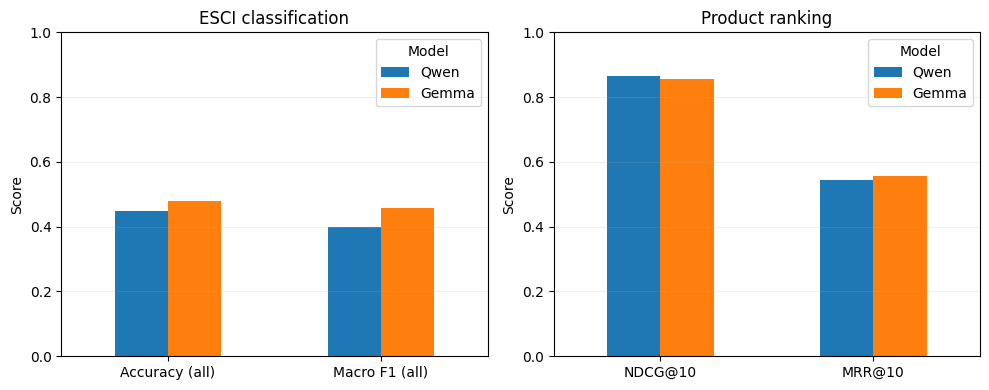

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cols, title in [
    (axes[0], ["Accuracy (all)", "Macro F1 (all)"], "ESCI classification"),
    (axes[1], ["NDCG@10", "MRR@10"], "Product ranking"),
]:
    summary[cols].T.plot(kind="bar", ax=ax, rot=0)
    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.legend(title="Model")
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "pair2_overall_metrics.png", dpi=180)
plt.show()

## 3. ESCI classification errors

Compare confusion matrices and per-class scores, especially Complement (C).

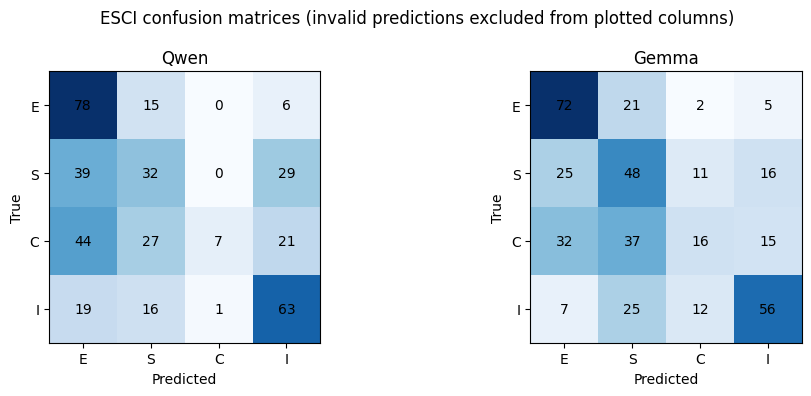

,Model,Label,Precision,Recall,F1
0,Qwen,E,0.433,0.78,0.557
1,Qwen,S,0.356,0.32,0.337
2,Qwen,C,0.875,0.07,0.130
3,Qwen,I,0.529,0.63,0.575
4,Gemma,E,0.529,0.72,0.610
5,Gemma,S,0.366,0.48,0.416
6,Gemma,C,0.390,0.16,0.227
7,Gemma,I,0.609,0.56,0.583


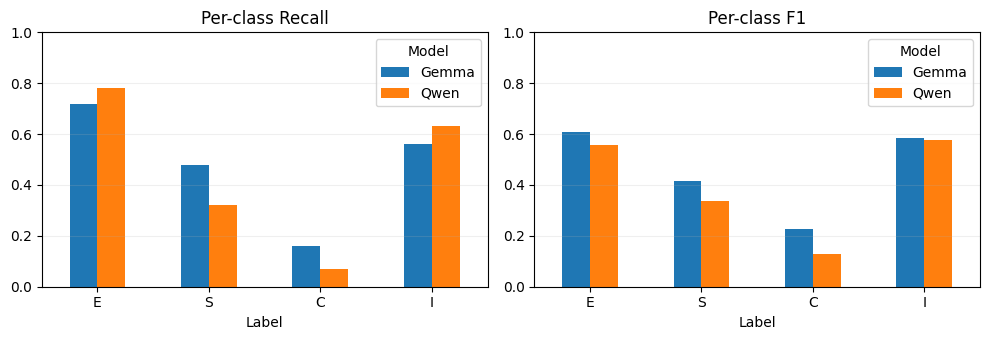

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, model in zip(axes, files):
    cm = confusion_matrix(paired["true_label"], paired[f"{model}_pred"].fillna("INVALID"), labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(model)
    ax.set_xticks(range(4), LABELS)
    ax.set_yticks(range(4), LABELS)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center")
fig.suptitle("ESCI confusion matrices (invalid predictions excluded from plotted columns)")
fig.tight_layout()
fig.savefig(FIGURES / "pair2_confusion_matrices.png", dpi=180)
plt.show()

per_class = []
for model in files:
    pred = paired[f"{model}_pred"].fillna("INVALID")
    for label in LABELS:
        tp = ((paired["true_label"] == label) & (pred == label)).sum()
        actual = (paired["true_label"] == label).sum()
        predicted = (pred == label).sum()
        precision = tp / predicted if predicted else 0
        recall = tp / actual if actual else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
        per_class.append({"Model": model, "Label": label, "Precision": precision, "Recall": recall, "F1": f1})
class_scores = pd.DataFrame(per_class)
display(class_scores.round(3))
class_scores.to_csv(RESULTS / "comparison_per_class.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric in zip(axes, ["Recall", "F1"]):
    class_scores.pivot(index="Label", columns="Model", values=metric).reindex(LABELS).plot.bar(ax=ax, rot=0)
    ax.set_title(f"Per-class {metric}")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "pair2_class_metrics.png", dpi=180)
plt.show()

## 4. Example mistakes

Inspect real product queries that one or both models classified incorrectly.

In [15]:
dataset = BASE / "datasets" / "classification_cases.csv"
if not dataset.exists():
    raise FileNotFoundError(f"Missing {dataset}; needed to inspect actual product examples")
cases = pd.read_csv(dataset, dtype={"example_id": str})
examples = paired.reset_index().merge(
    cases[["example_id", "query", "product_title", "product_description"]],
    on="example_id", how="left", validate="one_to_one"
)
examples["Qwen_correct"] = examples["Qwen_pred"] == examples["true_label"]
examples["Gemma_correct"] = examples["Gemma_pred"] == examples["true_label"]
cols = ["query", "product_title", "true_label", "Qwen_pred", "Gemma_pred"]

print("Complement examples misclassified by both:")
display(examples[(examples["true_label"] == "C") & ~examples["Qwen_correct"] & ~examples["Gemma_correct"]][cols].head(8))
print("Gemma correct, Qwen incorrect:")
display(examples[~examples["Qwen_correct"] & examples["Gemma_correct"]][cols].head(6))
print("Qwen correct, Gemma incorrect:")
display(examples[examples["Qwen_correct"] & ~examples["Gemma_correct"]][cols].head(6))

print("Prediction agreement:", round((examples["Qwen_pred"] == examples["Gemma_pred"]).mean(), 3))
print("Both correct:", int((examples["Qwen_correct"] & examples["Gemma_correct"]).sum()))
print("Both incorrect:", int((~examples["Qwen_correct"] & ~examples["Gemma_correct"]).sum()))

Complement examples misclassified by both:


,query,product_title,true_label,Qwen_pred,Gemma_pred
2,fitbit charge 3,NANW 2-Pack Charger Compatible with Fitbit Cha...,C,S,E
4,throw pillows for couch,"MIULEE Pack of 2, Velvet Soft Solid Decorative...",C,E,E
7,fitbit versa lite,TOYOUTHS Scrunchie Bands Compatible with Fitbi...,C,S,S
15,medella pump,"Medela Breast Milk Storage Bags, 100 Count, Re...",C,E,S
20,slide rider,Swimline Sturdy See-Thru Surf Rider Pool Float...,C,INVALID,I
21,double 24 inch bronze,"Hunter 26043 24-Inch Downrod, New Bronze",C,E,S
24,cardiac nurse badge card,"Nurse Badge Holder Reel, 3 Pcs Retractable Bad...",C,S,S
33,hydro flask 16 oz wide mouth,"PEMOTech Wide Mouth Straw Lid for Hydro-Flask,...",C,S,S


Gemma correct, Qwen incorrect:


,query,product_title,true_label,Qwen_pred,Gemma_pred
5,forest green bath mat,Towel Bazaar Premium Turkish Cotton Super Soft...,C,I,C
10,11/4 leather belt without buckle,30mm Ratchet Belt Buckle Only for 1 1/4 Slide ...,C,S,C
11,90x132 gold satin tablecloth,Surmente 90 x 156 Tablecloth for Rectangle Tab...,S,I,S
13,contact lens,Improve Your Vision Without Glasses or Contact...,C,I,C
18,back rack rear bar,MICTUNING Car Clothes Hanger Bar Expandable 36...,I,E,I
30,burts bees baby socks,"Gerber Baby Unisex 6 Pack Socks, White, 0-3 Mo...",S,E,S


Qwen correct, Gemma incorrect:


,query,product_title,true_label,Qwen_pred,Gemma_pred
9,organic bloom fertilizer liquid,Humboldts Secret Golden Tree: Best Plant Food ...,E,E,S
12,dyna-glo charcoal grill,Dyna-Glo DG443CBC Barrel Charcoal Grill Cover,C,C,S
34,light blue intense dolce and gabbana women,D & G Light Blue By Dolce & Gabbana For Men Ea...,I,I,S
47,head mic,PoP voice Premium 16 Feet Dual-head Lavalier M...,E,E,S
49,motor tool dewalt,"DEWALT 20V MAX Jig Saw, Barrel Grip, Tool Only...",E,E,S
84,dingy boat wheels,"Inflatable Boat Repair Kit, 3 X PVC Patch, 1 X...",I,I,C


Prediction agreement: 0.608
Both correct: 139
Both incorrect: 167


## 5. Ranking errors

Compare scores per query and examine the largest ranking disagreement.

,query,Qwen_ndcg,Gemma_ndcg,ndcg_diff_Gemma_minus_Qwen,Qwen_mrr,Gemma_mrr
query_id,,,,,,
25286,chemistry kit for kids 5-10,1.000,0.333,-0.667,1.000,0.143
13045,bape sweatpants,0.838,0.695,-0.142,0.167,0.125
111893,wine,0.790,0.676,-0.114,0.500,0.250
27800,colon clear formula,1.000,0.916,-0.084,1.000,0.500
1612,10oz tervis cups without lid,0.902,0.819,-0.083,0.500,0.167
105536,trx home suspension training kit,0.956,0.900,-0.056,1.000,1.000
11925,baby fleece suit,0.836,0.795,-0.041,0.250,0.143
69637,minnesota wild 3/4 zip,0.437,0.417,-0.020,0.250,0.200


Queries where Qwen NDCG is higher: 15
Queries where Gemma NDCG is higher: 10
Ties: 8


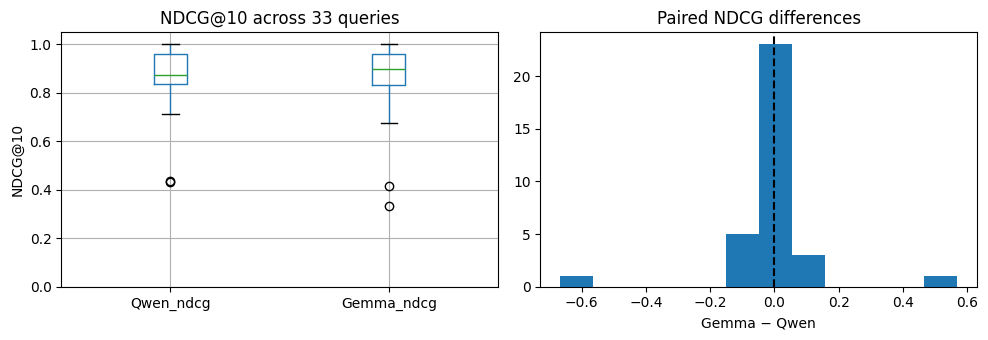

In [16]:
rank_paired["ndcg_diff_Gemma_minus_Qwen"] = rank_paired["Gemma_ndcg"] - rank_paired["Qwen_ndcg"]
rank_paired["mrr_diff_Gemma_minus_Qwen"] = rank_paired["Gemma_mrr"] - rank_paired["Qwen_mrr"]
display(rank_paired[["query", "Qwen_ndcg", "Gemma_ndcg", "ndcg_diff_Gemma_minus_Qwen", "Qwen_mrr", "Gemma_mrr"]]
        .sort_values("ndcg_diff_Gemma_minus_Qwen").head(8).round(3))
print("Queries where Qwen NDCG is higher:", int((rank_paired["ndcg_diff_Gemma_minus_Qwen"] < 0).sum()))
print("Queries where Gemma NDCG is higher:", int((rank_paired["ndcg_diff_Gemma_minus_Qwen"] > 0).sum()))
print("Ties:", int((rank_paired["ndcg_diff_Gemma_minus_Qwen"] == 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
rank_paired[["Qwen_ndcg", "Gemma_ndcg"]].boxplot(ax=axes[0])
axes[0].set_title("NDCG@10 across 33 queries")
axes[0].set_ylabel("NDCG@10")
axes[0].set_ylim(0, 1.05)
axes[1].hist(rank_paired["ndcg_diff_Gemma_minus_Qwen"].dropna(), bins=12)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Paired NDCG differences")
axes[1].set_xlabel("Gemma − Qwen")
fig.tight_layout()
fig.savefig(FIGURES / "pair2_ranking_distribution.png", dpi=180)
plt.show()

In [17]:
rank_cases = pd.read_csv(BASE / "datasets" / "ranking_cases.csv", dtype={"query_id": str, "product_id": str})
rank_lookup = {str(k): v.reset_index(drop=True) for k, v in rank_cases.groupby("query_id", sort=False)}

def show_ranking(query_id):
    query_id = str(query_id)
    group = rank_lookup[query_id]
    print("Query:", group.iloc[0]["query"])
    print("Ground truth: E = Exact, S = Substitute, C = Complement, I = Irrelevant")
    result = {}
    for model in files:
        row = ranking[model].set_index("query_id").loc[query_id]
        order = json.loads(row["predicted_order"])
        result[model] = [group.iloc[i-1]["esci_label"] for i in order]
    display(pd.DataFrame({
        "Position": range(1, 11),
        "Qwen label": result["Qwen"],
        "Gemma label": result["Gemma"],
    }))
    for model in files:
        row = ranking[model].set_index("query_id").loc[query_id]
        order = json.loads(row["predicted_order"])
        print(f"\n{model} top 5 products:")
        for pos, i in enumerate(order[:5], 1):
            product = group.iloc[i-1]
            print(f" {pos}. [{product['esci_label']}] {str(product['product_title'])[:115]}")

# Inspect the largest difference in ranking quality
qid = rank_paired["ndcg_diff_Gemma_minus_Qwen"].abs().idxmax()
show_ranking(qid)

Query: chemistry kit for kids 5-10
Ground truth: E = Exact, S = Substitute, C = Complement, I = Irrelevant


,Position,Qwen label,Gemma label
0,1,E,I
1,2,I,I
2,3,I,I
3,4,I,I
4,5,I,I
5,6,I,I
6,7,I,E
7,8,I,I
8,9,I,I
9,10,I,I



Qwen top 5 products:
 1. [E] Ben Franklin Toys Chemistry Lab Pad Science Kit
 2. [I] Kids Science Kit - Over 60 Experiments, Gift for Kids Ages 8 -12
 3. [I] Kids Science Experiment Kit with Lab Coat Scientist Costume Dress Up and Role Play Toys Gift for Boys Girls Kids Ag
 4. [I] Be Amazing! Toys Big Bag of Science Works - Kids Science Experiment Kit with 65+ Amazing Experiments - Set Up Your 
 5. [I] Kitchen Science Lab for Kids: 52 Family Friendly Experiments from Around the House (Volume 4) (Lab for Kids, 4)

Gemma top 5 products:
 1. [I] Kids Science Experiment Kit with Lab Coat Scientist Costume Dress Up and Role Play Toys Gift for Boys Girls Kids Ag
 2. [I] Kids Science Kit with Lab Coat Gift Set - Over 20 Experiments for Kids 4-6
 3. [I] Science Kit for Kids - 21 Experiments Science Set, Great Gifts for 6, 7, 8 , 9+ Year Old Girls and Boys
 4. [I] Kids Science Kit - Over 60 Experiments, Gift for Kids Ages 8 -12
 5. [I] Be Amazing! Toys Big Bag of Science Works - Kids Science E

## 6. Uncertainty

A paired bootstrap estimates the uncertainty in the differences. Small samples can produce unstable results.

In [18]:
rng = np.random.default_rng(42)

def paired_bootstrap(a, b, n_boot=3000):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    good = np.isfinite(a) & np.isfinite(b)
    differences = (b - a)[good]
    if not len(differences):
        return (np.nan, np.nan, np.nan)
    inds = rng.integers(0, len(differences), size=(n_boot, len(differences)))
    return (differences.mean(), *np.percentile(differences[inds].mean(axis=1), [2.5, 97.5]))

# For classification, compare paired correctness (Gemma minus Qwen)
qcorrect = (paired["Qwen_pred"] == paired["true_label"]).astype(int)
gcorrect = (paired["Gemma_pred"] == paired["true_label"]).astype(int)
checks = {
    "Classification accuracy difference": paired_bootstrap(qcorrect, gcorrect),
    "NDCG@10 difference": paired_bootstrap(rank_paired["Qwen_ndcg"], rank_paired["Gemma_ndcg"]),
    "MRR@10 difference": paired_bootstrap(rank_paired["Qwen_mrr"], rank_paired["Gemma_mrr"]),
}
uncertainty = pd.DataFrame(checks, index=["Gemma − Qwen", "95% lower", "95% upper"]).T
display(uncertainty.round(3))
uncertainty.to_csv(RESULTS / "comparison_bootstrap.csv")

,Gemma − Qwen,95% lower,95% upper
Classification accuracy difference,0.030,-0.018,0.078
NDCG@10 difference,-0.008,-0.063,0.046
MRR@10 difference,0.014,-0.077,0.107


## 7. Discussion

### Classification Performance

Gemma performed better than Qwen in ESCI classification, achieving 48.0% accuracy and 0.459 Macro F1, compared with Qwen's 45.0% accuracy and 0.400 Macro F1. Gemma also returned valid labels for all 400 examples, while Qwen produced three invalid responses. However, the 95% bootstrap confidence interval for the accuracy difference (−0.018 to 0.078) includes zero, so the results do not establish a clear performance advantage.

Both models struggled most with Complement (C) products. Qwen correctly classified only 7 of 100 Complement examples, while Gemma correctly classified 16 of 100. For example, both models misclassified a Fitbit charger as either an Exact match or Substitute for a Fitbit Charge 3. Similarly, both incorrectly classified a Hydro Flask straw lid. This suggests that the models often recognise related products but struggle to distinguish accessories from products that directly satisfy or replace a customer's search.

### Ranking Performance

Qwen achieved slightly higher NDCG@10 (0.866 versus 0.857), while Gemma achieved slightly higher MRR@10 (0.557 versus 0.543). Qwen outperformed Gemma on 15 queries, Gemma performed better on 10, and both tied on eight. The bootstrap confidence intervals include zero, indicating that neither model demonstrated a clear ranking advantage.

One noticeable example was the query "chemistry kit for kids 5-10". Qwen ranked the Exact product first, achieving NDCG@10 of 1.000, while Gemma placed it seventh, resulting in NDCG@10 of 0.333. This shows that a model may identify products that appear relevant but still fail to prioritise the most appropriate result.

Although both models achieved relatively high ranking scores, their classification performance was much weaker. This is partly because ranking and classification measure different abilities. Ranking evaluates the order of products within a candidate list, while classification requires the model to distinguish four specific relevance categories.

### Efficiency and Practical Implications

Gemma was slightly faster, averaging 0.166 seconds per classification compared with Qwen's 0.203 seconds. For ranking, Gemma averaged 0.702 seconds compared with Qwen's 0.737 seconds. These differences may matter when processing large numbers of customer searches, although the experiment only measures local inference under the tested configurations.

For Amazon, incorrect product classifications could reduce search relevance and customer satisfaction. In particular, displaying accessories as Exact matches could cause customers to receive results that do not directly satisfy their searches. Based on the observed results, Gemma is a reasonable provisional choice for classification, while Qwen remains competitive for ranking. However, neither model is sufficiently reliable to replace an existing product-search system without further evaluation.

### Limitations

The classification experiment used 400 balanced examples, while the ranking experiment used only 33 selected queries containing one Exact product and nine non-Exact products each. These samples may not represent real Amazon search traffic. The evaluation was also limited to English-language queries, quantised models and a single prompting approach.

Future work could evaluate more queries, include multilingual searches, test alternative prompts and compare both models against a traditional retrieval baseline such as BM25. A combined retrieval and LLM reranking system may also provide a more practical solution for Amazon.

## 8. Reproducibility

Data: Amazon Shopping Queries ESCI, US English, official test split (400 classification cases, 33 ranking queries). Models: Qwen3.5-4B Q4_K_M and Gemma 4 E4B Q4_0, using `llama-server`. Individual notebooks contain prompts, inference settings, and results. This notebook reads saved CSVs and writes comparison figures and metrics to `results/`.